#### Importing Libraries

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
torch.set_num_threads(2)

processed_dir = Path("../data/processed")
models_dir = Path("../models")
artifacts_dir = Path("../artifacts")

models_dir.mkdir(parents=True, exist_ok=True)
artifacts_dir.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


#### Loading Datasets and Model Configurations

In [2]:
daily_df = pd.read_csv(
    processed_dir / "daily_reservations.csv",
    parse_dates=["arrival_datetime"]
)

train_df = pd.read_csv(
    processed_dir / "train_daily.csv",
    parse_dates=["arrival_datetime"]
)

test_df = pd.read_csv(
    processed_dir / "test_daily.csv",
    parse_dates=["arrival_datetime"]
)

train_features_df = pd.read_csv(
    processed_dir / "train_features.csv",
    parse_dates=["arrival_datetime"]
)

test_features_df = pd.read_csv(
    processed_dir / "test_features.csv",
    parse_dates=["arrival_datetime"]
)

model_comparison_df = pd.read_csv(
    artifacts_dir / "model_comparison.csv"
)

with open(
    artifacts_dir / "selected_model_configurations.json",
    "r",
    encoding="utf-8"
) as file:
    selected_config = json.load(file)

date_column = "arrival_datetime"
target_column = "scheduled_reservations"

forecast_horizon = selected_config["forecast_horizon"]

feature_columns = [
    column
    for column in train_features_df.columns
    if column not in [date_column, target_column]
]

print("Datasets Loaded Successfully\n")

print(f"Complete Daily Dataset: {daily_df.shape}")
print(f"Training Dataset: {train_df.shape}")
print(f"Testing Dataset: {test_df.shape}")
print(f"Training Features: {train_features_df.shape}")
print(f"Testing Features: {test_features_df.shape}")

print(f"\nForecast Horizon: {forecast_horizon} days")
print(f"Total Features: {len(feature_columns)}")

print("\nTraining Period:")
print(
    f"{train_df[date_column].min().date()} to "
    f"{train_df[date_column].max().date()}"
)

print("\nTesting Period:")
print(
    f"{test_df[date_column].min().date()} to "
    f"{test_df[date_column].max().date()}"
)

print("\nSelected Models:")
for model_name in selected_config["selected_models"]:
    print(f"- {model_name}")

print("\nValidation Performance:")
display(
    model_comparison_df[
        model_comparison_df["Model"].isin(
            selected_config["selected_models"]
        )
    ].round(4)
)

Datasets Loaded Successfully

Complete Daily Dataset: (549, 2)
Training Dataset: (439, 2)
Testing Dataset: (110, 2)
Training Features: (405, 26)
Testing Features: (110, 26)

Forecast Horizon: 7 days
Total Features: 24

Training Period:
2017-07-01 to 2018-09-12

Testing Period:
2018-09-13 to 2018-12-31

Selected Models:
- Weighted Averaging
- Tuned LSTM
- Tuned SARIMA
- Tuned Extra Trees

Validation Performance:


,Model,MAE,RMSE,WAPE,R2,Validation_Folds
0,Weighted Averaging,24.8586,29.5802,27.0050,-0.2174,22
1,Tuned LSTM,24.9624,30.2994,26.9607,-0.3110,22
3,Tuned SARIMA,25.3564,30.0178,27.4934,-0.2436,22
5,Tuned Extra Trees,25.6465,30.7887,28.0721,-0.4364,22


#### Key Observations
- **Chronological Data Separation Is Preserved:** The training period contains 439 days ending September 12, 2018, while the untouched test period contains 110 days from September 13 to December 31, 2018.
- **Forecasting Inputs Are Ready for Evaluation:** All four shortlisted models are identified, with 24 engineered features available for evaluating seven-day forecasts.

#### Constructing Rolling Forecast Windows

In [3]:
test_df = test_df.sort_values(date_column).reset_index(drop=True)
train_df = train_df.sort_values(date_column).reset_index(drop=True)

forecast_windows = []

for start_idx in range(0, len(test_df), forecast_horizon):
    end_idx = min(start_idx + forecast_horizon, len(test_df))

    window_df = test_df.iloc[start_idx:end_idx]

    forecast_origin = (
        train_df[date_column].max()
        if start_idx == 0
        else test_df.loc[start_idx - 1, date_column]
    )

    forecast_windows.append({
        "Window": len(forecast_windows) + 1,
        "Forecast_Origin": forecast_origin,
        "Forecast_Start": window_df[date_column].iloc[0],
        "Forecast_End": window_df[date_column].iloc[-1],
        "Forecast_Days": len(window_df),
        "Start_Index": start_idx,
        "End_Index": end_idx
    })

forecast_windows_df = pd.DataFrame(forecast_windows)

assert forecast_windows_df["Forecast_Days"].sum() == len(test_df)

assert (
    forecast_windows_df["Forecast_Start"].iloc[0]
    == test_df[date_column].min()
)

assert (
    forecast_windows_df["Forecast_End"].iloc[-1]
    == test_df[date_column].max()
)

assert (
    forecast_windows_df["Forecast_Days"].between(
        1, forecast_horizon
    ).all()
)

print("Rolling Forecast Windows:")
display(
    forecast_windows_df[
        [
            "Window",
            "Forecast_Origin",
            "Forecast_Start",
            "Forecast_End",
            "Forecast_Days"
        ]
    ]
)

print(f"\nTotal Forecast Windows: {len(forecast_windows_df)}")
print(f"Complete Seven-Day Windows: {(forecast_windows_df['Forecast_Days'] == 7).sum()}")
print(f"Total Forecast Days: {forecast_windows_df['Forecast_Days'].sum()}")

Rolling Forecast Windows:


,Window,Forecast_Origin,Forecast_Start,Forecast_End,Forecast_Days
0,1,2018-09-12,2018-09-13,2018-09-19,7
1,2,2018-09-19,2018-09-20,2018-09-26,7
2,3,2018-09-26,2018-09-27,2018-10-03,7
3,4,2018-10-03,2018-10-04,2018-10-10,7
4,5,2018-10-10,2018-10-11,2018-10-17,7
5,6,2018-10-17,2018-10-18,2018-10-24,7
6,7,2018-10-24,2018-10-25,2018-10-31,7
7,8,2018-10-31,2018-11-01,2018-11-07,7
8,9,2018-11-07,2018-11-08,2018-11-14,7
9,10,2018-11-14,2018-11-15,2018-11-21,7



Total Forecast Windows: 16
Complete Seven-Day Windows: 15
Total Forecast Days: 110


#### Key Observations
- **Complete Test Coverage Is Established:** The evaluation consists of 15 seven-day windows and one five-day window, covering all 110 test observations from September 13 to December 31, 2018.
- **Chronological Forecast Origins Are Preserved:** Each window begins immediately after its forecast origin, ensuring that predictions can be generated using only historical observations available at that point.

#### Defining Forecast Evaluation Functions

In [4]:
def evaluate_forecast(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()

    if y_true.shape != y_pred.shape:
        raise ValueError(
            "Actual and predicted values must have matching shapes."
        )

    if not np.isfinite(y_true).all() or not np.isfinite(y_pred).all():
        raise ValueError(
            "Actual and predicted values must be finite."
        )

    y_pred = np.maximum(y_pred, 0)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    actual_total = np.abs(y_true).sum()

    wape = (
        np.abs(y_true - y_pred).sum() / actual_total * 100
        if actual_total > 0
        else np.nan
    )

    r2 = (
        r2_score(y_true, y_pred)
        if len(y_true) >= 2
        else np.nan
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE": wape,
        "R2": r2
    }


def record_forecast(
    model_name,
    window,
    actual,
    predicted
):
    actual = np.asarray(actual, dtype=float).ravel()
    predicted = np.maximum(
        np.asarray(predicted, dtype=float).ravel(),
        0
    )

    if len(actual) != len(predicted):
        raise ValueError(
            "Actual and predicted values must have matching lengths."
        )

    metrics = evaluate_forecast(actual, predicted)

    result = {
        "Model": model_name,
        "Window": int(window["Window"]),
        "Forecast_Days": len(actual),
        **metrics
    }

    predictions = []

    forecast_dates = test_df.iloc[
        int(window["Start_Index"]):int(window["End_Index"])
    ][date_column].to_numpy()

    for step, (forecast_date, actual_value, predicted_value) in enumerate(
        zip(forecast_dates, actual, predicted),
        start=1
    ):
        predictions.append({
            "Model": model_name,
            "Window": int(window["Window"]),
            "Forecast_Origin": window["Forecast_Origin"],
            "Forecast_Date": forecast_date,
            "Forecast_Step": step,
            "Actual": float(actual_value),
            "Predicted": float(predicted_value),
            "Absolute_Error": abs(actual_value - predicted_value)
        })

    return result, predictions


test_results = []
test_predictions = []

print("Forecast evaluation functions defined successfully.")
print(f"Total Evaluation Windows: {len(forecast_windows_df)}")
print(f"Selected Models: {len(selected_config['selected_models'])}")

Forecast evaluation functions defined successfully.
Total Evaluation Windows: 16
Selected Models: 4


#### Retrieving Original Model Configurations

In [5]:
print("Original Weighted Averaging Components:")
for model_name, weight in selected_config["weighted_averaging"]["components"].items():
    print(f"{model_name}: {weight:.0%}")

print("\nOriginal Model Configurations Required:")
print("LSTM: Lookback, hidden units, learning rate, weight decay, epochs")
print("SARIMA: Order, seasonal order, trend, fitting settings")
print("Extra Trees: Estimators, maximum depth, minimum split, minimum leaf, feature sampling")

print("\nAvailable Tuned Configurations:")
for model_name in ["tuned_lstm", "tuned_sarima", "tuned_extra_trees"]:
    print(f"\n{model_name}:")
    print(json.dumps(selected_config[model_name], indent=4))

print("\nOriginal Model Definitions:")
for model_name in ["LSTMForecaster"]:
    print(
        f"{model_name}: "
        f"{'Available' if model_name in globals() else 'Not defined in this notebook'}"
    )

Original Weighted Averaging Components:
LSTM: 40%
SARIMA: 35%
Extra Trees: 25%

Original Model Configurations Required:
LSTM: Lookback, hidden units, learning rate, weight decay, epochs
SARIMA: Order, seasonal order, trend, fitting settings
Extra Trees: Estimators, maximum depth, minimum split, minimum leaf, feature sampling

Available Tuned Configurations:

tuned_lstm:
{
    "lookback": 14,
    "hidden_size": 16,
    "learning_rate": 0.001,
    "weight_decay": 0.001,
    "epochs": 100
}

tuned_sarima:
{
    "order": [
        1,
        1,
        1
    ],
    "seasonal_order": [
        1,
        0,
        0,
        7
    ],
    "enforce_stationarity": false,
    "enforce_invertibility": false,
    "maxiter": 100
}

tuned_extra_trees:
{
    "n_estimators": 100,
    "min_samples_split": 2,
    "min_samples_leaf": 4,
    "max_features": 0.7,
    "max_depth": 12,
    "random_state": 42,
    "n_jobs": -1
}

Original Model Definitions:
LSTMForecaster: Not defined in this notebook


#### Preserving Original Ensemble Configurations

In [6]:
original_model_configurations = {
    "lstm": {
        "lookback": 28,
        "input_size": 1,
        "hidden_size": 16,
        "num_layers": 1,
        "batch_first": True,
        "learning_rate": 0.001,
        "weight_decay": 0.001,
        "epochs": 100,
        "loss_function": "MSELoss",
        "optimizer": "Adam",
        "scaler": "StandardScaler"
    },
    "sarima": {
        "order": [1, 1, 1],
        "seasonal_order": [1, 0, 1, 7],
        "trend": "n",
        "enforce_stationarity": False,
        "enforce_invertibility": False,
        "maxiter": 100
    },
    "extra_trees": {
        "n_estimators": 200,
        "max_depth": 8,
        "min_samples_split": 10,
        "min_samples_leaf": 4,
        "max_features": 0.8,
        "random_state": RANDOM_STATE,
        "n_jobs": -1
    }
}

selected_config["original_models"] = original_model_configurations

config_path = artifacts_dir / "selected_model_configurations.json"

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(selected_config, file, indent=4)

print("Original Model Configurations Saved Successfully\n")

for model_name, configuration in original_model_configurations.items():
    print(f"{model_name.upper()}:")
    print(json.dumps(configuration, indent=4))
    print()

print(f"Configuration File: {config_path}")
print(f"Original Models Preserved: {len(original_model_configurations)}")
print(
    "Ensemble Weights Preserved:",
    selected_config["weighted_averaging"]["components"]
)

Original Model Configurations Saved Successfully

LSTM:
{
    "lookback": 28,
    "input_size": 1,
    "hidden_size": 16,
    "num_layers": 1,
    "batch_first": true,
    "learning_rate": 0.001,
    "weight_decay": 0.001,
    "epochs": 100,
    "loss_function": "MSELoss",
    "optimizer": "Adam",
    "scaler": "StandardScaler"
}

SARIMA:
{
    "order": [
        1,
        1,
        1
    ],
    "seasonal_order": [
        1,
        0,
        1,
        7
    ],
    "trend": "n",
    "enforce_stationarity": false,
    "enforce_invertibility": false,
    "maxiter": 100
}

EXTRA_TREES:
{
    "n_estimators": 200,
    "max_depth": 8,
    "min_samples_split": 10,
    "min_samples_leaf": 4,
    "max_features": 0.8,
    "random_state": 42,
    "n_jobs": -1
}

Configuration File: ..\artifacts\selected_model_configurations.json
Original Models Preserved: 3
Ensemble Weights Preserved: {'LSTM': 0.4, 'SARIMA': 0.35, 'Extra Trees': 0.25}


#### Defining the LSTM Architecture

In [7]:
class LSTMForecaster(nn.Module):
    def __init__(self, hidden_size=16):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.output = nn.Linear(
            hidden_size,
            forecast_horizon
        )

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        return self.output(hidden[-1])


original_lstm_config = selected_config["original_models"]["lstm"]
tuned_lstm_config = selected_config["tuned_lstm"]

original_lstm = LSTMForecaster(
    hidden_size=original_lstm_config["hidden_size"]
)

tuned_lstm = LSTMForecaster(
    hidden_size=tuned_lstm_config["hidden_size"]
)

print("LSTM Architecture Defined Successfully\n")

print("Original LSTM Configuration:")
print(f"Lookback: {original_lstm_config['lookback']} days")
print(f"Hidden Units: {original_lstm_config['hidden_size']}")
print(f"Epochs: {original_lstm_config['epochs']}")

print("\nTuned LSTM Configuration:")
print(f"Lookback: {tuned_lstm_config['lookback']} days")
print(f"Hidden Units: {tuned_lstm_config['hidden_size']}")
print(f"Epochs: {tuned_lstm_config['epochs']}")

print("\nOriginal LSTM Architecture:")
print(original_lstm)

LSTM Architecture Defined Successfully

Original LSTM Configuration:
Lookback: 28 days
Hidden Units: 16
Epochs: 100

Tuned LSTM Configuration:
Lookback: 14 days
Hidden Units: 16
Epochs: 100

Original LSTM Architecture:
LSTMForecaster(
  (lstm): LSTM(1, 16, batch_first=True)
  (output): Linear(in_features=16, out_features=7, bias=True)
)


#### Defining the LSTM Forecasting Function

In [8]:
def generate_lstm_forecast(history, config):
    history = np.asarray(history, dtype=np.float32).ravel()

    lookback = int(config["lookback"])
    hidden_size = int(config["hidden_size"])
    epochs = int(config["epochs"])
    learning_rate = float(config["learning_rate"])
    weight_decay = float(config["weight_decay"])

    if len(history) < lookback + forecast_horizon:
        raise ValueError(
            "Insufficient historical observations for LSTM training."
        )

    scaler = StandardScaler()

    scaled_history = scaler.fit_transform(
        history.reshape(-1, 1)
    ).ravel()

    X_sequences = []
    y_sequences = []

    for start in range(
        len(scaled_history) - lookback - forecast_horizon + 1
    ):
        X_sequences.append(
            scaled_history[start:start + lookback]
        )

        y_sequences.append(
            scaled_history[
                start + lookback:
                start + lookback + forecast_horizon
            ]
        )

    X_tensor = torch.tensor(
        np.array(X_sequences),
        dtype=torch.float32
    ).unsqueeze(-1)

    y_tensor = torch.tensor(
        np.array(y_sequences),
        dtype=torch.float32
    )

    torch.manual_seed(RANDOM_STATE)

    model = LSTMForecaster(
        hidden_size=hidden_size
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    criterion = nn.MSELoss()

    model.train()

    for epoch in range(epochs):
        optimizer.zero_grad()

        predictions = model(X_tensor)
        loss = criterion(predictions, y_tensor)

        loss.backward()
        optimizer.step()

    model.eval()

    input_sequence = torch.tensor(
        scaled_history[-lookback:],
        dtype=torch.float32
    ).reshape(1, lookback, 1)

    with torch.no_grad():
        scaled_forecast = (
            model(input_sequence)
            .numpy()
            .reshape(-1, 1)
        )

    forecast = scaler.inverse_transform(
        scaled_forecast
    ).ravel()

    return np.maximum(forecast, 0)


print("LSTM Forecasting Function Defined Successfully")

print("\nSupported Configurations:")
print(
    f"Original LSTM: "
    f"{original_lstm_config['lookback']}-day lookback"
)
print(
    f"Tuned LSTM: "
    f"{tuned_lstm_config['lookback']}-day lookback"
)
print(f"Forecast Horizon: {forecast_horizon} days")

LSTM Forecasting Function Defined Successfully

Supported Configurations:
Original LSTM: 28-day lookback
Tuned LSTM: 14-day lookback
Forecast Horizon: 7 days


#### Defining the SARIMA Forecasting Function

In [9]:
def generate_sarima_forecast(history, config):
    history = np.asarray(history, dtype=float).ravel()

    if len(history) < 2 * forecast_horizon:
        raise ValueError(
            "Insufficient historical observations for SARIMA forecasting."
        )

    if not np.isfinite(history).all():
        raise ValueError(
            "Historical observations contain non-finite values."
        )

    model = SARIMAX(
        history,
        order=tuple(config["order"]),
        seasonal_order=tuple(config["seasonal_order"]),
        trend=config.get("trend", "n"),
        enforce_stationarity=config["enforce_stationarity"],
        enforce_invertibility=config["enforce_invertibility"]
    )

    fitted_model = model.fit(
        disp=False,
        maxiter=int(config["maxiter"])
    )

    forecast = np.asarray(
        fitted_model.forecast(steps=forecast_horizon),
        dtype=float
    ).ravel()

    if not np.isfinite(forecast).all():
        raise ValueError(
            "SARIMA produced non-finite forecast values."
        )

    return np.maximum(forecast, 0)


original_sarima_config = selected_config["original_models"]["sarima"]
tuned_sarima_config = selected_config["tuned_sarima"]

print("SARIMA Forecasting Function Defined Successfully")

print("\nOriginal SARIMA Configuration:")
print(f"Order: {tuple(original_sarima_config['order'])}")
print(f"Seasonal Order: {tuple(original_sarima_config['seasonal_order'])}")

print("\nTuned SARIMA Configuration:")
print(f"Order: {tuple(tuned_sarima_config['order'])}")
print(f"Seasonal Order: {tuple(tuned_sarima_config['seasonal_order'])}")

print(f"\nForecast Horizon: {forecast_horizon} days")

SARIMA Forecasting Function Defined Successfully

Original SARIMA Configuration:
Order: (1, 1, 1)
Seasonal Order: (1, 0, 1, 7)

Tuned SARIMA Configuration:
Order: (1, 1, 1)
Seasonal Order: (1, 0, 0, 7)

Forecast Horizon: 7 days


#### Defining the Extra Trees Forecasting Function

In [10]:
def generate_extra_trees_forecast(
    training_features,
    forecasting_features,
    config
):
    if training_features.empty:
        raise ValueError(
            "No training observations available for Extra Trees."
        )

    if forecasting_features.empty:
        raise ValueError(
            "No forecasting observations available for Extra Trees."
        )

    X_train = training_features[feature_columns]
    y_train = training_features[target_column]

    X_forecast = forecasting_features[feature_columns]

    if (
        X_train.isna().any().any()
        or X_forecast.isna().any().any()
    ):
        raise ValueError(
            "Extra Trees features contain missing values."
        )

    model = ExtraTreesRegressor(
        n_estimators=int(config["n_estimators"]),
        max_depth=config["max_depth"],
        min_samples_split=int(config["min_samples_split"]),
        min_samples_leaf=int(config["min_samples_leaf"]),
        max_features=config["max_features"],
        random_state=int(config["random_state"]),
        n_jobs=int(config["n_jobs"])
    )

    model.fit(X_train, y_train)

    forecast = np.asarray(
        model.predict(X_forecast),
        dtype=float
    ).ravel()

    if not np.isfinite(forecast).all():
        raise ValueError(
            "Extra Trees produced non-finite forecast values."
        )

    return np.maximum(forecast, 0)


original_extra_trees_config = selected_config["original_models"]["extra_trees"]
tuned_extra_trees_config = selected_config["tuned_extra_trees"]

print("Extra Trees Forecasting Function Defined Successfully")

print("\nOriginal Extra Trees Configuration:")
print(f"Estimators: {original_extra_trees_config['n_estimators']}")
print(f"Maximum Depth: {original_extra_trees_config['max_depth']}")
print(f"Minimum Leaf Samples: {original_extra_trees_config['min_samples_leaf']}")

print("\nTuned Extra Trees Configuration:")
print(f"Estimators: {tuned_extra_trees_config['n_estimators']}")
print(f"Maximum Depth: {tuned_extra_trees_config['max_depth']}")
print(f"Minimum Leaf Samples: {tuned_extra_trees_config['min_samples_leaf']}")

print(f"\nForecast Horizon: {forecast_horizon} days")

Extra Trees Forecasting Function Defined Successfully

Original Extra Trees Configuration:
Estimators: 200
Maximum Depth: 8
Minimum Leaf Samples: 4

Tuned Extra Trees Configuration:
Estimators: 100
Maximum Depth: 12
Minimum Leaf Samples: 4

Forecast Horizon: 7 days


#### Verifying Forecast Feature Availability

In [13]:
import re

feature_source_df = (
    pd.concat(
        [train_features_df, test_features_df],
        ignore_index=True
    )
    .sort_values(date_column)
    .reset_index(drop=True)
)

feature_source_df[date_column] = pd.to_datetime(
    feature_source_df[date_column]
)

calendar_features = {
    "year",
    "quarter",
    "month",
    "day_of_month",
    "day_of_week",
    "day_of_year",
    "week_of_year",
    "is_weekend",
    "is_month_start",
    "is_month_end"
}

feature_availability = []

for feature in feature_columns:
    if feature in calendar_features:
        minimum_lag = None
        availability = "Known in Advance"
        safe = True

    else:
        lag_match = re.fullmatch(r"reservations_lag_(\d+)", feature)

        if lag_match:
            minimum_lag = int(lag_match.group(1))
        else:
            minimum_lag = (
                7
                if feature.startswith(
                    ("rolling_", "expanding_", "trend_")
                )
                else None
            )

        safe = (
            minimum_lag is not None
            and minimum_lag >= forecast_horizon
        )

        availability = (
            "Historical Only"
            if safe
            else "Requires Verification"
        )

    feature_availability.append({
        "Feature": feature,
        "Availability": availability,
        "Minimum_Lag": minimum_lag,
        "Safe": safe
    })

feature_availability_df = pd.DataFrame(
    feature_availability
)

expected_dates = pd.date_range(
    daily_df[date_column].min(),
    daily_df[date_column].max(),
    freq="D"
)

assert len(daily_df) == len(expected_dates), (
    "The daily series contains missing dates."
)

assert (
    daily_df[date_column].reset_index(drop=True)
    == pd.Series(expected_dates)
).all(), "The daily series is not chronologically continuous."

assert feature_availability_df["Safe"].all(), (
    "Some features may require future observations."
)

assert not feature_source_df[feature_columns].isna().any().any(), (
    "Missing values detected in engineered features."
)

assert all(
    window["Forecast_Days"] <= forecast_horizon
    for _, window in forecast_windows_df.iterrows()
), "A forecast window exceeds the seven-day horizon."

print("Forecast Feature Availability Verified Successfully")

print(f"\nTotal Features: {len(feature_columns)}")
print(
    "Calendar Features:",
    feature_availability_df["Availability"]
    .eq("Known in Advance")
    .sum()
)
print(
    "Historical Features:",
    feature_availability_df["Availability"]
    .eq("Historical Only")
    .sum()
)
print(
    "Features Requiring Verification:",
    (~feature_availability_df["Safe"]).sum()
)
print(f"Forecast Windows: {len(forecast_windows_df)}")
print(f"Maximum Forecast Horizon: {forecast_horizon} days")

print("\nFeature Availability Summary:")
display(feature_availability_df)

Forecast Feature Availability Verified Successfully

Total Features: 24
Calendar Features: 10
Historical Features: 14
Features Requiring Verification: 0
Forecast Windows: 16
Maximum Forecast Horizon: 7 days

Feature Availability Summary:


,Feature,Availability,Minimum_Lag,Safe
0,year,Known in Advance,NaN,True
1,quarter,Known in Advance,NaN,True
2,month,Known in Advance,NaN,True
3,day_of_month,Known in Advance,NaN,True
4,day_of_week,Known in Advance,NaN,True
5,day_of_year,Known in Advance,NaN,True
6,week_of_year,Known in Advance,NaN,True
7,is_weekend,Known in Advance,NaN,True
8,is_month_start,Known in Advance,NaN,True
9,is_month_end,Known in Advance,NaN,True


#### Identifying Unverified Forecast Features

In [12]:
unverified_features_df = feature_availability_df.loc[
    ~feature_availability_df["Safe"],
    ["Feature", "Availability", "Minimum_Lag"]
].copy()

print("Forecast Feature Verification Diagnostics")
print(f"\nTotal Features: {len(feature_columns)}")
print(f"Verified Features: {feature_availability_df['Safe'].sum()}")
print(f"Unverified Features: {len(unverified_features_df)}")

print("\nFeatures Requiring Investigation:")
display(unverified_features_df)

print("\nComplete Feature Names:")
for feature in feature_columns:
    print(feature)

Forecast Feature Verification Diagnostics

Total Features: 24
Verified Features: 20
Unverified Features: 4

Features Requiring Investigation:


,Feature,Availability,Minimum_Lag
10,reservations_lag_7,Requires Verification,NaN
11,reservations_lag_14,Requires Verification,NaN
12,reservations_lag_21,Requires Verification,NaN
13,reservations_lag_28,Requires Verification,NaN



Complete Feature Names:
year
quarter
month
day_of_month
day_of_week
day_of_year
week_of_year
is_weekend
is_month_start
is_month_end
reservations_lag_7
reservations_lag_14
reservations_lag_21
reservations_lag_28
rolling_mean_7
rolling_std_7
rolling_mean_14
rolling_std_14
rolling_mean_28
rolling_std_28
expanding_mean
expanding_std
trend_7_day
trend_14_day


#### Validating Historical Feature Calculations

In [14]:
historical_series = (
    daily_df
    .sort_values(date_column)
    .set_index(date_column)[target_column]
    .astype(float)
)

expected_features = pd.DataFrame(
    index=historical_series.index
)

for lag in [7, 14, 21, 28]:
    expected_features[f"reservations_lag_{lag}"] = (
        historical_series.shift(lag)
    )

shifted_history = historical_series.shift(forecast_horizon)

for window_size in [7, 14, 28]:
    expected_features[f"rolling_mean_{window_size}"] = (
        shifted_history.rolling(window_size).mean()
    )

    expected_features[f"rolling_std_{window_size}"] = (
        shifted_history.rolling(window_size).std()
    )

expected_features["expanding_mean"] = (
    shifted_history.expanding().mean()
)

expected_features["expanding_std"] = (
    shifted_history.expanding().std()
)

expected_features["trend_7_day"] = (
    shifted_history.rolling(7).mean()
)

expected_features["trend_14_day"] = (
    shifted_history.rolling(14).mean()
)

actual_features = (
    feature_source_df
    .set_index(date_column)
    .sort_index()
)

historical_feature_columns = [
    feature
    for feature in feature_columns
    if feature not in calendar_features
]

comparison_results = []

for feature in historical_feature_columns:
    actual_values = actual_features[feature].to_numpy(dtype=float)

    expected_values = (
        expected_features
        .loc[actual_features.index, feature]
        .to_numpy(dtype=float)
    )

    matches = np.isclose(
        actual_values,
        expected_values,
        rtol=1e-6,
        atol=1e-6,
        equal_nan=True
    )

    comparison_results.append({
        "Feature": feature,
        "Matching_Observations": int(matches.sum()),
        "Total_Observations": len(matches),
        "Verified": bool(matches.all())
    })

feature_calculation_df = pd.DataFrame(comparison_results)

print("Historical Feature Calculation Verification")

display(feature_calculation_df)

print(
    f"\nVerified Historical Features: "
    f"{feature_calculation_df['Verified'].sum()}"
    f"/{len(historical_feature_columns)}"
)

if feature_calculation_df["Verified"].all():
    print("\nAll Historical Feature Calculations Verified Successfully")
else:
    print("\nSome Feature Calculations Require Investigation")

Historical Feature Calculation Verification


,Feature,Matching_Observations,Total_Observations,Verified
0,reservations_lag_7,515,515,True
1,reservations_lag_14,515,515,True
2,reservations_lag_21,515,515,True
3,reservations_lag_28,515,515,True
4,rolling_mean_7,515,515,True
5,rolling_std_7,515,515,True
6,rolling_mean_14,515,515,True
7,rolling_std_14,515,515,True
8,rolling_mean_28,515,515,True
9,rolling_std_28,515,515,True



Verified Historical Features: 12/14

Some Feature Calculations Require Investigation


#### Investigating Trend Feature Calculations

In [15]:
trend_diagnostics = actual_features[
    ["trend_7_day", "trend_14_day"]
].copy()

trend_diagnostics["rolling_mean_7"] = (
    actual_features["rolling_mean_7"]
)

trend_diagnostics["rolling_mean_14"] = (
    actual_features["rolling_mean_14"]
)

trend_diagnostics["rolling_difference"] = (
    trend_diagnostics["rolling_mean_7"]
    - trend_diagnostics["rolling_mean_14"]
)

trend_diagnostics["rolling_ratio"] = (
    trend_diagnostics["rolling_mean_7"]
    / trend_diagnostics["rolling_mean_14"].replace(0, np.nan)
)

trend_diagnostics["trend_7_minus_rolling_7"] = (
    trend_diagnostics["trend_7_day"]
    - trend_diagnostics["rolling_mean_7"]
)

trend_diagnostics["trend_14_minus_rolling_14"] = (
    trend_diagnostics["trend_14_day"]
    - trend_diagnostics["rolling_mean_14"]
)

print("Trend Feature Diagnostics")

display(
    trend_diagnostics.head(10).round(4)
)

print("\nTrend Feature Summary:")
display(
    trend_diagnostics[
        ["trend_7_day", "trend_14_day"]
    ].describe().round(4)
)

print("\nCorrelation With Rolling Features:")
display(
    trend_diagnostics[
        [
            "trend_7_day",
            "trend_14_day",
            "rolling_mean_7",
            "rolling_mean_14",
            "rolling_difference"
        ]
    ].corr().round(4)
)

Trend Feature Diagnostics


,trend_7_day,trend_14_day,rolling_mean_7,rolling_mean_14,rolling_difference,rolling_ratio,trend_7_minus_rolling_7,trend_14_minus_rolling_14
arrival_datetime,,,,,,,,
2017-08-04,-6.8571,-1.0714,8.1429,11.5714,-3.4286,0.7037,-15.0000,-12.6429
2017-08-05,-6.4286,3.7143,8.7143,11.9286,-3.2143,0.7305,-15.1429,-8.2143
2017-08-06,-5.8571,3.6429,9.0000,11.9286,-2.9286,0.7545,-14.8571,-8.2857
2017-08-07,2.8571,-3.6429,9.8571,8.4286,1.4286,1.1695,-7.0000,-12.0714
2017-08-08,3.0000,-4.7143,10.4286,8.9286,1.5000,1.1680,-7.4286,-13.6429
2017-08-09,3.7143,-4.7857,10.8571,9.0000,1.8571,1.2063,-7.1429,-13.7857
2017-08-10,3.0000,-4.2143,10.7143,9.2143,1.5000,1.1628,-7.7143,-13.4286
2017-08-11,3.2857,-2.7143,11.4286,9.7857,1.6429,1.1679,-8.1429,-12.5000
2017-08-12,8.4286,0.4286,17.1429,12.9286,4.2143,1.3260,-8.7143,-12.5000



Trend Feature Summary:


,trend_7_day,trend_14_day
count,515.0000,515.0000
mean,0.5173,1.2811
std,19.6745,15.9465
min,-64.1429,-45.3571
25%,-10.0714,-6.8571
50%,0.8571,1.3571
75%,12.4286,11.8214
max,46.4286,46.6429



Correlation With Rolling Features:


,trend_7_day,trend_14_day,rolling_mean_7,rolling_mean_14,rolling_difference
trend_7_day,1.0000,0.1200,0.2866,-0.0344,1.0000
trend_14_day,0.1200,1.0000,0.2157,0.1850,0.1200
rolling_mean_7,0.2866,0.2157,1.0000,0.9476,0.2866
rolling_mean_14,-0.0344,0.1850,0.9476,1.0000,-0.0344
rolling_difference,1.0000,0.1200,0.2866,-0.0344,1.0000


#### Verifying Trend Feature Formulas

In [16]:
shifted_history = historical_series.shift(forecast_horizon)

trend_candidates = {
    "trend_7_day": {
        "Recent 7 vs Previous 7": (
            shifted_history.rolling(7).mean()
            - shifted_history.shift(7).rolling(7).mean()
        )
    },
    "trend_14_day": {
        "Recent 14 vs Previous 14": (
            shifted_history.rolling(14).mean()
            - shifted_history.shift(14).rolling(14).mean()
        ),
        "Recent 14 vs Previous 7": (
            shifted_history.rolling(14).mean()
            - shifted_history.shift(14).rolling(7).mean()
        ),
        "Recent 7 vs Previous 14": (
            shifted_history.rolling(7).mean()
            - shifted_history.shift(7).rolling(14).mean()
        )
    }
}

trend_verification_results = []

for feature, candidates in trend_candidates.items():
    actual_values = actual_features[feature].to_numpy(dtype=float)

    for formula_name, expected_series in candidates.items():
        expected_values = expected_series.loc[
            actual_features.index
        ].to_numpy(dtype=float)

        matches = np.isclose(
            actual_values,
            expected_values,
            rtol=1e-6,
            atol=1e-6,
            equal_nan=True
        )

        trend_verification_results.append({
            "Feature": feature,
            "Formula": formula_name,
            "Matching_Observations": int(matches.sum()),
            "Total_Observations": len(matches),
            "Verified": bool(matches.all())
        })

trend_verification_df = pd.DataFrame(
    trend_verification_results
)

print("Trend Formula Verification Results:")
display(trend_verification_df)

Trend Formula Verification Results:


,Feature,Formula,Matching_Observations,Total_Observations,Verified
0,trend_7_day,Recent 7 vs Previous 7,515,515,True
1,trend_14_day,Recent 14 vs Previous 14,515,515,True
2,trend_14_day,Recent 14 vs Previous 7,0,515,False
3,trend_14_day,Recent 7 vs Previous 14,1,515,False


**Key Observations**

- **Historical Feature Consistency:** All 14 historical features match independently reconstructed calculations across 515 observations, confirming that the saved feature-engineering pipeline consistently applies the intended transformations.
- **Forecasting Leakage Prevention:** Both trend features compare historical periods using a seven-day shift. Together with the lag, rolling, expanding, and calendar features, this ensures that the predictors are available at the forecast origin for the seven-day prediction horizon.

#### Preparing Rolling-Origin Evaluation Data

In [17]:
def prepare_forecast_window(window):
    forecast_origin = pd.Timestamp(
        window["Forecast_Origin"]
    )

    forecast_start = pd.Timestamp(
        window["Forecast_Start"]
    )

    forecast_end = pd.Timestamp(
        window["Forecast_End"]
    )

    history = daily_df.loc[
        daily_df[date_column] <= forecast_origin
    ].copy()

    training_features = feature_source_df.loc[
        feature_source_df[date_column] <= forecast_origin
    ].copy()

    forecasting_features = feature_source_df.loc[
        feature_source_df[date_column].between(
            forecast_start,
            forecast_end
        )
    ].copy()

    actual = test_df.loc[
        test_df[date_column].between(
            forecast_start,
            forecast_end
        ),
        target_column
    ].to_numpy(dtype=float)

    expected_days = int(window["Forecast_Days"])

    if (
        len(forecasting_features) != expected_days
        or len(actual) != expected_days
    ):
        raise ValueError(
            "Forecast window contains an unexpected number of observations."
        )

    if history[date_column].max() != forecast_origin:
        raise ValueError(
            "Historical observations do not end at the forecast origin."
        )

    if training_features[date_column].max() != forecast_origin:
        raise ValueError(
            "Training features do not end at the forecast origin."
        )

    return {
        "history": history,
        "training_features": training_features,
        "forecasting_features": forecasting_features,
        "actual": actual
    }


first_window = prepare_forecast_window(
    forecast_windows_df.iloc[0]
)

last_window = prepare_forecast_window(
    forecast_windows_df.iloc[-1]
)

print("Rolling-Origin Evaluation Data Prepared Successfully")

print("\nFirst Forecast Window:")
print(f"Historical Days: {len(first_window['history'])}")
print(f"Training Feature Rows: {len(first_window['training_features'])}")
print(f"Forecast Days: {len(first_window['actual'])}")

print("\nFinal Forecast Window:")
print(f"Historical Days: {len(last_window['history'])}")
print(f"Training Feature Rows: {len(last_window['training_features'])}")
print(f"Forecast Days: {len(last_window['actual'])}")

print(f"\nTotal Evaluation Windows: {len(forecast_windows_df)}")

Rolling-Origin Evaluation Data Prepared Successfully

First Forecast Window:
Historical Days: 439
Training Feature Rows: 405
Forecast Days: 7

Final Forecast Window:
Historical Days: 544
Training Feature Rows: 510
Forecast Days: 5

Total Evaluation Windows: 16


#### Evaluating the Tuned LSTM Model

In [18]:
model_name = "Tuned LSTM"

tuned_lstm_results = []
tuned_lstm_predictions = []

for _, window in forecast_windows_df.iterrows():
    window_data = prepare_forecast_window(window)

    history = window_data["history"][
        target_column
    ].to_numpy(dtype=np.float32)

    actual = window_data["actual"]

    predicted = generate_lstm_forecast(
        history,
        tuned_lstm_config
    )[:len(actual)]

    result, predictions = record_forecast(
        model_name,
        window,
        actual,
        predicted
    )

    tuned_lstm_results.append(result)
    tuned_lstm_predictions.extend(predictions)

    print(
        f"Window {int(window['Window']):02d}/"
        f"{len(forecast_windows_df)} Completed"
    )

test_results = [
    result
    for result in test_results
    if result["Model"] != model_name
]

test_predictions = [
    prediction
    for prediction in test_predictions
    if prediction["Model"] != model_name
]

test_results.extend(tuned_lstm_results)
test_predictions.extend(tuned_lstm_predictions)

test_results_df = pd.DataFrame(test_results)
test_predictions_df = pd.DataFrame(test_predictions)

test_comparison_df = pd.DataFrame([
    {
        "Model": name,
        **evaluate_forecast(
            group["Actual"].to_numpy(),
            group["Predicted"].to_numpy()
        ),
        "Forecast_Days": len(group),
        "Evaluation_Windows": group["Window"].nunique()
    }
    for name, group in test_predictions_df.groupby("Model")
]).sort_values("MAE").reset_index(drop=True)

test_results_df.to_csv(
    artifacts_dir / "model_test_results.csv",
    index=False
)

test_predictions_df.to_csv(
    artifacts_dir / "model_test_predictions.csv",
    index=False
)

test_comparison_df.to_csv(
    artifacts_dir / "model_test_comparison.csv",
    index=False
)

print("\nTuned LSTM Test Evaluation Completed Successfully")

print("\nUpdated Test Model Comparison:")
display(test_comparison_df.round(4))

best_model = test_comparison_df.iloc[0]

print(f"\nTotal Models Evaluated: {test_comparison_df['Model'].nunique()}")
print(f"Best Performing Model: {best_model['Model']}")
print(f"Best Model MAE: {best_model['MAE']:.4f}")

Window 01/16 Completed
Window 02/16 Completed
Window 03/16 Completed
Window 04/16 Completed
Window 05/16 Completed
Window 06/16 Completed
Window 07/16 Completed
Window 08/16 Completed
Window 09/16 Completed
Window 10/16 Completed
Window 11/16 Completed
Window 12/16 Completed
Window 13/16 Completed
Window 14/16 Completed
Window 15/16 Completed
Window 16/16 Completed

Tuned LSTM Test Evaluation Completed Successfully

Updated Test Model Comparison:


,Model,MAE,RMSE,WAPE,R2,Forecast_Days,Evaluation_Windows
0,Tuned LSTM,32.0191,41.4961,36.2543,0.0156,110,16



Total Models Evaluated: 1
Best Performing Model: Tuned LSTM
Best Model MAE: 32.0191


**Key Observations**

- **Forecast Accuracy:** The Tuned LSTM achieved an MAE of 32.02 reservations, RMSE of 41.50, and WAPE of 36.25% across 110 test days, indicating substantial forecasting errors relative to actual reservation volumes.
- **Generalization Performance:** Test MAE increased from 24.96 during validation to 32.02, while the test R² of 0.0156 indicates limited explanatory performance on unseen observations.

#### Evaluating the Tuned SARIMA Model

In [19]:
model_name = "Tuned SARIMA"

tuned_sarima_results = []
tuned_sarima_predictions = []

for _, window in forecast_windows_df.iterrows():
    window_data = prepare_forecast_window(window)

    history = window_data["history"][
        target_column
    ].to_numpy(dtype=float)

    actual = window_data["actual"]

    predicted = generate_sarima_forecast(
        history,
        tuned_sarima_config
    )[:len(actual)]

    result, predictions = record_forecast(
        model_name,
        window,
        actual,
        predicted
    )

    tuned_sarima_results.append(result)
    tuned_sarima_predictions.extend(predictions)

    print(
        f"Window {int(window['Window']):02d}/"
        f"{len(forecast_windows_df)} Completed"
    )

test_results = [
    result
    for result in test_results
    if result["Model"] != model_name
]

test_predictions = [
    prediction
    for prediction in test_predictions
    if prediction["Model"] != model_name
]

test_results.extend(tuned_sarima_results)
test_predictions.extend(tuned_sarima_predictions)

test_results_df = pd.DataFrame(test_results)
test_predictions_df = pd.DataFrame(test_predictions)

test_comparison_df = pd.DataFrame([
    {
        "Model": name,
        **evaluate_forecast(
            group["Actual"].to_numpy(),
            group["Predicted"].to_numpy()
        ),
        "Forecast_Days": len(group),
        "Evaluation_Windows": group["Window"].nunique()
    }
    for name, group in test_predictions_df.groupby("Model")
]).sort_values("MAE").reset_index(drop=True)

test_results_df.to_csv(
    artifacts_dir / "model_test_results.csv",
    index=False
)

test_predictions_df.to_csv(
    artifacts_dir / "model_test_predictions.csv",
    index=False
)

test_comparison_df.to_csv(
    artifacts_dir / "model_test_comparison.csv",
    index=False
)

print("\nTuned SARIMA Test Evaluation Completed Successfully")

print("\nUpdated Test Model Comparison:")
display(test_comparison_df.round(4))

best_model = test_comparison_df.iloc[0]

print(f"\nTotal Models Evaluated: {test_comparison_df['Model'].nunique()}")
print(f"Best Performing Model: {best_model['Model']}")
print(f"Best Model MAE: {best_model['MAE']:.4f}")

Window 01/16 Completed
Window 02/16 Completed
Window 03/16 Completed
Window 04/16 Completed
Window 05/16 Completed
Window 06/16 Completed
Window 07/16 Completed
Window 08/16 Completed
Window 09/16 Completed
Window 10/16 Completed
Window 11/16 Completed
Window 12/16 Completed
Window 13/16 Completed
Window 14/16 Completed
Window 15/16 Completed
Window 16/16 Completed

Tuned SARIMA Test Evaluation Completed Successfully

Updated Test Model Comparison:


,Model,MAE,RMSE,WAPE,R2,Forecast_Days,Evaluation_Windows
0,Tuned SARIMA,30.5649,38.6199,34.6077,0.1473,110,16
1,Tuned LSTM,32.0191,41.4961,36.2543,0.0156,110,16



Total Models Evaluated: 2
Best Performing Model: Tuned SARIMA
Best Model MAE: 30.5649


**Key Observations**

- **Improved Forecast Accuracy:** Tuned SARIMA achieved an MAE of 30.56 reservations, RMSE of 38.62, and WAPE of 34.61%, outperforming Tuned LSTM across all three error metrics.
- **Generalization Performance:** Tuned SARIMA achieved an R² of 0.1473, compared with 0.0156 for Tuned LSTM, indicating better performance on unseen observations, although substantial forecasting uncertainty remains.

#### Evaluating the Tuned Extra Trees Model

In [20]:
model_name = "Tuned Extra Trees"

tuned_extra_trees_results = []
tuned_extra_trees_predictions = []

for _, window in forecast_windows_df.iterrows():
    window_data = prepare_forecast_window(window)

    training_features = window_data["training_features"]
    forecasting_features = window_data["forecasting_features"]
    actual = window_data["actual"]

    predicted = generate_extra_trees_forecast(
        training_features,
        forecasting_features,
        tuned_extra_trees_config
    )

    result, predictions = record_forecast(
        model_name,
        window,
        actual,
        predicted
    )

    tuned_extra_trees_results.append(result)
    tuned_extra_trees_predictions.extend(predictions)

    print(
        f"Window {int(window['Window']):02d}/"
        f"{len(forecast_windows_df)} Completed"
    )

test_results = [
    result
    for result in test_results
    if result["Model"] != model_name
]

test_predictions = [
    prediction
    for prediction in test_predictions
    if prediction["Model"] != model_name
]

test_results.extend(tuned_extra_trees_results)
test_predictions.extend(tuned_extra_trees_predictions)

test_results_df = pd.DataFrame(test_results)
test_predictions_df = pd.DataFrame(test_predictions)

test_comparison_df = pd.DataFrame([
    {
        "Model": name,
        **evaluate_forecast(
            group["Actual"].to_numpy(),
            group["Predicted"].to_numpy()
        ),
        "Forecast_Days": len(group),
        "Evaluation_Windows": group["Window"].nunique()
    }
    for name, group in test_predictions_df.groupby("Model")
]).sort_values("MAE").reset_index(drop=True)

test_results_df.to_csv(
    artifacts_dir / "model_test_results.csv",
    index=False
)

test_predictions_df.to_csv(
    artifacts_dir / "model_test_predictions.csv",
    index=False
)

test_comparison_df.to_csv(
    artifacts_dir / "model_test_comparison.csv",
    index=False
)

print("\nTuned Extra Trees Test Evaluation Completed Successfully")

print("\nUpdated Test Model Comparison:")
display(test_comparison_df.round(4))

best_model = test_comparison_df.iloc[0]

print(f"\nTotal Models Evaluated: {test_comparison_df['Model'].nunique()}")
print(f"Best Performing Model: {best_model['Model']}")
print(f"Best Model MAE: {best_model['MAE']:.4f}")

Window 01/16 Completed
Window 02/16 Completed
Window 03/16 Completed
Window 04/16 Completed
Window 05/16 Completed
Window 06/16 Completed
Window 07/16 Completed
Window 08/16 Completed
Window 09/16 Completed
Window 10/16 Completed
Window 11/16 Completed
Window 12/16 Completed
Window 13/16 Completed
Window 14/16 Completed
Window 15/16 Completed
Window 16/16 Completed

Tuned Extra Trees Test Evaluation Completed Successfully

Updated Test Model Comparison:


,Model,MAE,RMSE,WAPE,R2,Forecast_Days,Evaluation_Windows
0,Tuned Extra Trees,29.0500,37.2760,32.8924,0.2056,110,16
1,Tuned SARIMA,30.5649,38.6199,34.6077,0.1473,110,16
2,Tuned LSTM,32.0191,41.4961,36.2543,0.0156,110,16



Total Models Evaluated: 3
Best Performing Model: Tuned Extra Trees
Best Model MAE: 29.0500


**Key Observations**

- **Strongest Individual Model:** Tuned Extra Trees achieved the lowest MAE (29.05), RMSE (37.28), and WAPE (32.89%) among the three evaluated models, demonstrating comparatively stronger forecasting accuracy.
- **Generalization Performance:** The model achieved an R² of 0.2056, outperforming Tuned SARIMA (0.1473) and Tuned LSTM (0.0156), although considerable variation in daily reservation volumes remains unexplained.

#### Evaluating the Weighted Averaging Ensemble

In [21]:
model_name = "Weighted Averaging"

ensemble_weights = selected_config["weighted_averaging"]["components"]

weighted_results = []
weighted_predictions = []

for _, window in forecast_windows_df.iterrows():
    window_data = prepare_forecast_window(window)

    history = window_data["history"][
        target_column
    ].to_numpy(dtype=float)

    training_features = window_data["training_features"]
    forecasting_features = window_data["forecasting_features"]
    actual = window_data["actual"]

    lstm_forecast = generate_lstm_forecast(
        history,
        original_lstm_config
    )[:len(actual)]

    sarima_forecast = generate_sarima_forecast(
        history,
        original_sarima_config
    )[:len(actual)]

    extra_trees_forecast = generate_extra_trees_forecast(
        training_features,
        forecasting_features,
        original_extra_trees_config
    )

    predicted = (
        ensemble_weights["LSTM"] * lstm_forecast
        + ensemble_weights["SARIMA"] * sarima_forecast
        + ensemble_weights["Extra Trees"] * extra_trees_forecast
    )

    predicted = np.maximum(predicted, 0)

    result, predictions = record_forecast(
        model_name,
        window,
        actual,
        predicted
    )

    weighted_results.append(result)
    weighted_predictions.extend(predictions)

    print(
        f"Window {int(window['Window']):02d}/"
        f"{len(forecast_windows_df)} Completed"
    )

test_results = [
    result
    for result in test_results
    if result["Model"] != model_name
]

test_predictions = [
    prediction
    for prediction in test_predictions
    if prediction["Model"] != model_name
]

test_results.extend(weighted_results)
test_predictions.extend(weighted_predictions)

test_results_df = pd.DataFrame(test_results)
test_predictions_df = pd.DataFrame(test_predictions)

test_comparison_df = pd.DataFrame([
    {
        "Model": name,
        **evaluate_forecast(
            group["Actual"].to_numpy(),
            group["Predicted"].to_numpy()
        ),
        "Forecast_Days": len(group),
        "Evaluation_Windows": group["Window"].nunique()
    }
    for name, group in test_predictions_df.groupby("Model")
]).sort_values("MAE").reset_index(drop=True)

test_results_df.to_csv(
    artifacts_dir / "model_test_results.csv",
    index=False
)

test_predictions_df.to_csv(
    artifacts_dir / "model_test_predictions.csv",
    index=False
)

test_comparison_df.to_csv(
    artifacts_dir / "model_test_comparison.csv",
    index=False
)

print("\nWeighted Averaging Test Evaluation Completed Successfully")

print("\nFinal Test Model Comparison:")
display(test_comparison_df.round(4))

best_model = test_comparison_df.iloc[0]

print(f"\nTotal Models Evaluated: {test_comparison_df['Model'].nunique()}")
print(f"Lowest Test MAE: {best_model['Model']}")
print(f"Best Test MAE: {best_model['MAE']:.4f}")
print(
    "Validation-Selected Primary Model:",
    selected_config["primary_model"]
)

Window 01/16 Completed
Window 02/16 Completed
Window 03/16 Completed
Window 04/16 Completed
Window 05/16 Completed
Window 06/16 Completed
Window 07/16 Completed
Window 08/16 Completed
Window 09/16 Completed
Window 10/16 Completed
Window 11/16 Completed
Window 12/16 Completed
Window 13/16 Completed
Window 14/16 Completed
Window 15/16 Completed
Window 16/16 Completed

Weighted Averaging Test Evaluation Completed Successfully

Final Test Model Comparison:


,Model,MAE,RMSE,WAPE,R2,Forecast_Days,Evaluation_Windows
0,Tuned Extra Trees,29.0500,37.2760,32.8924,0.2056,110,16
1,Weighted Averaging,29.2473,37.6373,33.1158,0.1901,110,16
2,Tuned SARIMA,30.5649,38.6199,34.6077,0.1473,110,16
3,Tuned LSTM,32.0191,41.4961,36.2543,0.0156,110,16



Total Models Evaluated: 4
Lowest Test MAE: Tuned Extra Trees
Best Test MAE: 29.0500
Validation-Selected Primary Model: Weighted Averaging


**Key Observations**

- **Competitive Ensemble Performance:** Weighted Averaging achieved an MAE of 29.25, RMSE of 37.64, and WAPE of 33.12%, demonstrating competitive forecasting accuracy across the 110-day test period.
- **Model Generalization:** Tuned Extra Trees recorded the lowest test MAE (29.05), outperforming Weighted Averaging by only 0.20 reservations per day. The ensemble remains the validation-selected primary model, while the small test performance difference highlights their comparable predictive accuracy.

#### Comparing Validation and Test Performance

In [22]:
validation_test_comparison_df = (
    model_comparison_df[
        ["Model", "MAE", "RMSE", "WAPE", "R2"]
    ]
    .merge(
        test_comparison_df[
            ["Model", "MAE", "RMSE", "WAPE", "R2"]
        ],
        on="Model",
        how="inner",
        suffixes=("_Validation", "_Test")
    )
)

validation_test_comparison_df["MAE_Change"] = (
    validation_test_comparison_df["MAE_Test"]
    - validation_test_comparison_df["MAE_Validation"]
)

validation_test_comparison_df["MAE_Change_Pct"] = (
    validation_test_comparison_df["MAE_Change"]
    / validation_test_comparison_df["MAE_Validation"]
    * 100
)

validation_test_comparison_df = (
    validation_test_comparison_df
    .sort_values("MAE_Validation")
    .reset_index(drop=True)
)

validation_test_comparison_df.to_csv(
    artifacts_dir / "validation_test_comparison.csv",
    index=False
)

print("Validation and Test Performance Comparison")

display(
    validation_test_comparison_df.round(4)
)

print(
    "\nValidation-Selected Primary Model:",
    selected_config["primary_model"]
)

print(
    "Lowest Test MAE:",
    test_comparison_df.iloc[0]["Model"]
)

print(
    "\nModels Compared:",
    len(validation_test_comparison_df)
)

Validation and Test Performance Comparison


,Model,MAE_Validation,RMSE_Validation,WAPE_Validation,R2_Validation,MAE_Test,RMSE_Test,WAPE_Test,R2_Test,MAE_Change,MAE_Change_Pct
0,Weighted Averaging,24.8586,29.5802,27.0050,-0.2174,29.2473,37.6373,33.1158,0.1901,4.3887,17.6545
1,Tuned LSTM,24.9624,30.2994,26.9607,-0.3110,32.0191,41.4961,36.2543,0.0156,7.0567,28.2693
2,Tuned SARIMA,25.3564,30.0178,27.4934,-0.2436,30.5649,38.6199,34.6077,0.1473,5.2085,20.5412
3,Tuned Extra Trees,25.6465,30.7887,28.0721,-0.4364,29.0500,37.2760,32.8924,0.2056,3.4034,13.2705



Validation-Selected Primary Model: Weighted Averaging
Lowest Test MAE: Tuned Extra Trees

Models Compared: 4


**Key Observations**

- **Generalization Gap:** All four models recorded higher test MAE than validation MAE, with increases ranging from 13.27% to 28.27%. Tuned Extra Trees demonstrated the smallest deterioration, while Tuned LSTM experienced the largest.
- **Model Ranking Changes:** Weighted Averaging achieved the lowest validation MAE (24.86), whereas Tuned Extra Trees achieved the lowest test MAE (29.05). The ensemble remains the validation-selected primary model, with both approaches delivering closely comparable test accuracy.

#### Analyzing Forecast Error Distributions

In [23]:
error_analysis_df = test_predictions_df.copy()

error_analysis_df["Error"] = (
    error_analysis_df["Actual"]
    - error_analysis_df["Predicted"]
)

error_analysis_df["Absolute_Error"] = (
    error_analysis_df["Error"].abs()
)

error_analysis_df["Squared_Error"] = (
    error_analysis_df["Error"] ** 2
)

error_summary_df = (
    error_analysis_df
    .groupby("Model", as_index=False)
    .agg(
        Mean_Error=("Error", "mean"),
        Median_Error=("Error", "median"),
        Mean_Absolute_Error=("Absolute_Error", "mean"),
        Median_Absolute_Error=("Absolute_Error", "median"),
        Error_Std=("Error", "std"),
        Maximum_Absolute_Error=("Absolute_Error", "max"),
        Overpredictions=("Error", lambda x: (x < 0).sum()),
        Underpredictions=("Error", lambda x: (x > 0).sum()),
        Exact_Predictions=("Error", lambda x: (x == 0).sum())
    )
    .sort_values("Mean_Absolute_Error")
    .reset_index(drop=True)
)

error_summary_df["Overprediction_Pct"] = (
    error_summary_df["Overpredictions"]
    / (
        error_summary_df["Overpredictions"]
        + error_summary_df["Underpredictions"]
        + error_summary_df["Exact_Predictions"]
    )
    * 100
)

error_summary_df["Underprediction_Pct"] = (
    error_summary_df["Underpredictions"]
    / (
        error_summary_df["Overpredictions"]
        + error_summary_df["Underpredictions"]
        + error_summary_df["Exact_Predictions"]
    )
    * 100
)

error_analysis_df.to_csv(
    artifacts_dir / "forecast_error_analysis.csv",
    index=False
)

error_summary_df.to_csv(
    artifacts_dir / "forecast_error_summary.csv",
    index=False
)

print("Forecast Error Analysis Completed Successfully")

print("\nModel Error Distribution Summary:")
display(error_summary_df.round(4))

print(f"\nTotal Models Analyzed: {error_summary_df['Model'].nunique()}")
print(f"Total Forecast Observations: {len(error_analysis_df)}")

Forecast Error Analysis Completed Successfully

Model Error Distribution Summary:


,Model,Mean_Error,Median_Error,Mean_Absolute_Error,Median_Absolute_Error,Error_Std,Maximum_Absolute_Error,Overpredictions,Underpredictions,Exact_Predictions,Overprediction_Pct,Underprediction_Pct
0,Tuned Extra Trees,-2.9249,-9.2286,29.0500,23.6087,37.3311,146.7758,66,44,0,60.0000,40.0000
1,Weighted Averaging,0.5893,-5.3180,29.2473,23.7595,37.8049,153.3937,64,46,0,58.1818,41.8182
2,Tuned SARIMA,-2.3238,-10.3806,30.5649,26.5998,38.7263,147.5447,66,44,0,60.0000,40.0000
3,Tuned LSTM,5.4497,-1.0493,32.0191,28.6513,41.3250,171.4450,56,54,0,50.9091,49.0909



Total Models Analyzed: 4
Total Forecast Observations: 440


**Key Observations**

- **Forecasting Bias:** Weighted Averaging recorded the smallest mean error (0.59 reservations), indicating the lowest overall signed bias. Tuned Extra Trees achieved the lowest MAE (29.05) but overpredicted on 60% of test days.
- **Error Variability:** Tuned Extra Trees recorded the lowest error standard deviation (37.33), while Tuned LSTM exhibited the greatest variability (41.33) and largest individual absolute error (171.45), highlighting differences in forecasting stability.

#### Visualizing Actual and Predicted Reservations

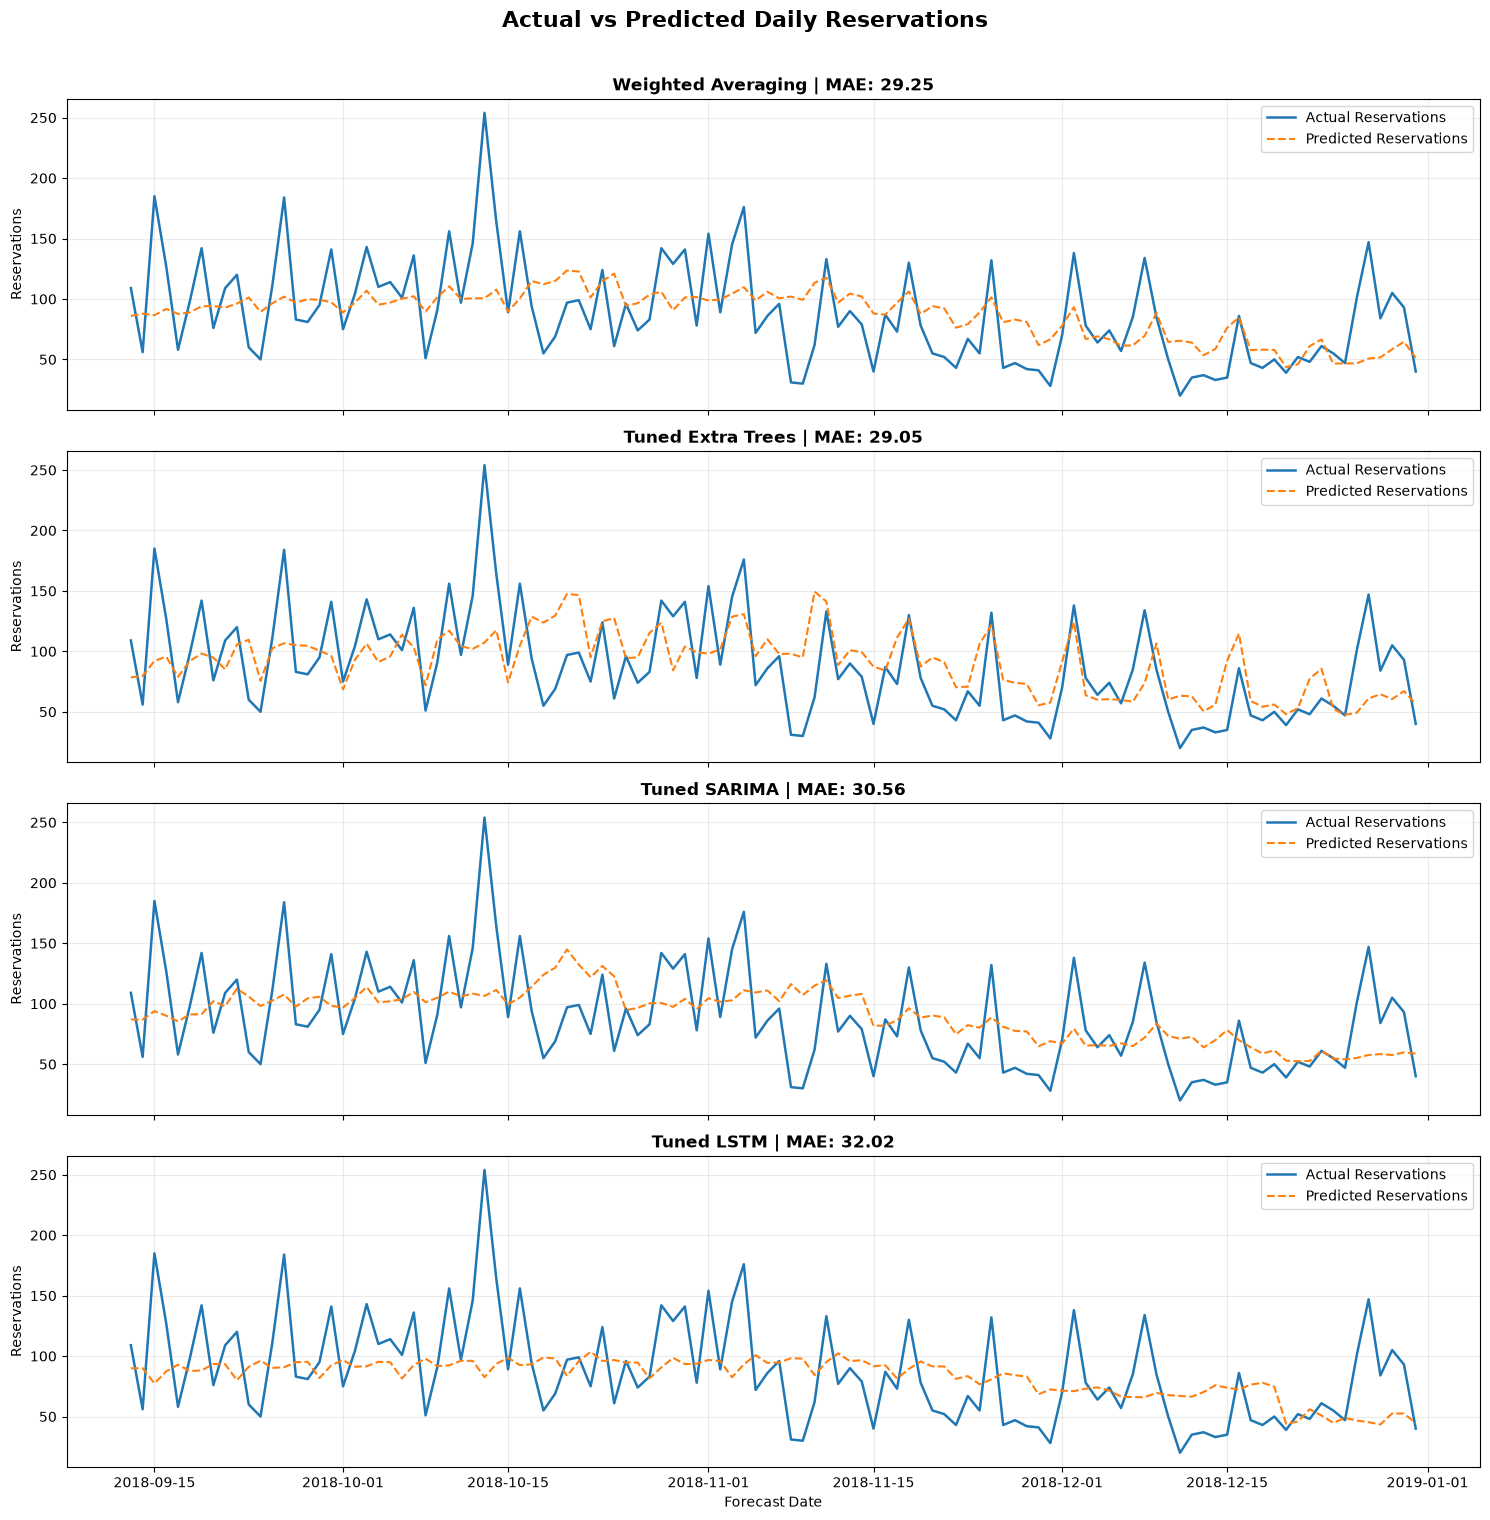

Actual vs Predicted Reservations Visualization Saved Successfully


In [24]:
plot_df = test_predictions_df.copy()

plot_df["Forecast_Date"] = pd.to_datetime(
    plot_df["Forecast_Date"]
)

plot_df = plot_df.sort_values(
    ["Model", "Forecast_Date"]
)

fig, axes = plt.subplots(
    4, 1,
    figsize=(15, 15),
    sharex=True
)

model_order = [
    "Weighted Averaging",
    "Tuned Extra Trees",
    "Tuned SARIMA",
    "Tuned LSTM"
]

for ax, model_name in zip(axes, model_order):
    model_data = plot_df[
        plot_df["Model"] == model_name
    ]

    ax.plot(
        model_data["Forecast_Date"],
        model_data["Actual"],
        label="Actual Reservations",
        linewidth=1.8
    )

    ax.plot(
        model_data["Forecast_Date"],
        model_data["Predicted"],
        label="Predicted Reservations",
        linewidth=1.5,
        linestyle="--"
    )

    model_mae = test_comparison_df.loc[
        test_comparison_df["Model"] == model_name,
        "MAE"
    ].iloc[0]

    ax.set_title(
        f"{model_name} | MAE: {model_mae:.2f}",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_ylabel("Reservations")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Forecast Date")

fig.suptitle(
    "Actual vs Predicted Daily Reservations",
    fontsize=16,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()

figure_path = artifacts_dir.parent / "reports" / "figures"
figure_path.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_path / "actual_vs_predicted_reservations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Actual vs Predicted Reservations Visualization Saved Successfully")

#### Analyzing Forecast Horizon Performance

In [25]:
horizon_performance_df = (
    test_predictions_df
    .groupby(["Model", "Forecast_Step"])
    .apply(
        lambda group: pd.Series({
            **evaluate_forecast(
                group["Actual"].to_numpy(),
                group["Predicted"].to_numpy()
            ),
            "Observations": len(group)
        }),
        include_groups=False
    )
    .reset_index()
    .sort_values(["Model", "Forecast_Step"])
    .reset_index(drop=True)
)

horizon_performance_df["Observations"] = (
    horizon_performance_df["Observations"].astype(int)
)

horizon_performance_df.to_csv(
    artifacts_dir / "forecast_horizon_performance.csv",
    index=False
)

print("Forecast Horizon Performance Analysis Completed Successfully")

print("\nMAE by Forecast Horizon:")
display(
    horizon_performance_df.pivot(
        index="Forecast_Step",
        columns="Model",
        values="MAE"
    ).round(4)
)

print("\nComplete Horizon Performance:")
display(horizon_performance_df.round(4))

print(f"\nModels Analyzed: {horizon_performance_df['Model'].nunique()}")
print(f"Forecast Steps Analyzed: {horizon_performance_df['Forecast_Step'].nunique()}")

Forecast Horizon Performance Analysis Completed Successfully

MAE by Forecast Horizon:


Model,Tuned Extra Trees,Tuned LSTM,Tuned SARIMA,Weighted Averaging
Forecast_Step,,,,
1,30.6853,31.2920,32.7220,30.1285
2,24.9333,27.0150,27.0360,25.9754
3,47.5985,40.6276,38.6822,40.6858
4,28.2354,40.4603,34.0290,30.5683
5,17.9616,24.9725,26.3852,21.0753
6,19.6214,24.3577,20.5433,21.3984
7,34.0367,35.1240,34.1546,34.7527



Complete Horizon Performance:


,Model,Forecast_Step,MAE,RMSE,WAPE,R2,Observations
0,Tuned Extra Trees,1,30.6853,39.8197,40.4086,-0.0756,16
1,Tuned Extra Trees,2,24.9333,30.5884,33.1340,0.0192,16
2,Tuned Extra Trees,3,47.5985,59.3737,45.8228,-0.2089,16
3,Tuned Extra Trees,4,28.2354,31.8620,23.7397,0.0799,16
4,Tuned Extra Trees,5,17.9616,20.6715,26.9341,0.0987,16
5,Tuned Extra Trees,6,19.6214,25.3198,23.0478,0.5460,15
6,Tuned Extra Trees,7,34.0367,39.5008,36.8097,0.1794,15
7,Tuned LSTM,1,31.2920,41.2252,41.2075,-0.1529,16
8,Tuned LSTM,2,27.0150,32.1514,35.9004,-0.0836,16
9,Tuned LSTM,3,40.6276,59.7879,39.1121,-0.2258,16



Models Analyzed: 4
Forecast Steps Analyzed: 7


**Key Observations**

- **Uneven Horizon Accuracy:** Forecast errors fluctuate across the seven-day horizon rather than increasing progressively. The third forecast step records the highest MAE for all four models, ranging from 38.68 to 47.60 reservations.
- **Model-Specific Performance:** Tuned Extra Trees achieves the lowest MAE at forecast steps 2, 4, 5, and 6, while Weighted Averaging performs best at step 1 and Tuned SARIMA at step 3. No single model consistently dominates every forecast step.

#### Visualizing Forecast Horizon Performance

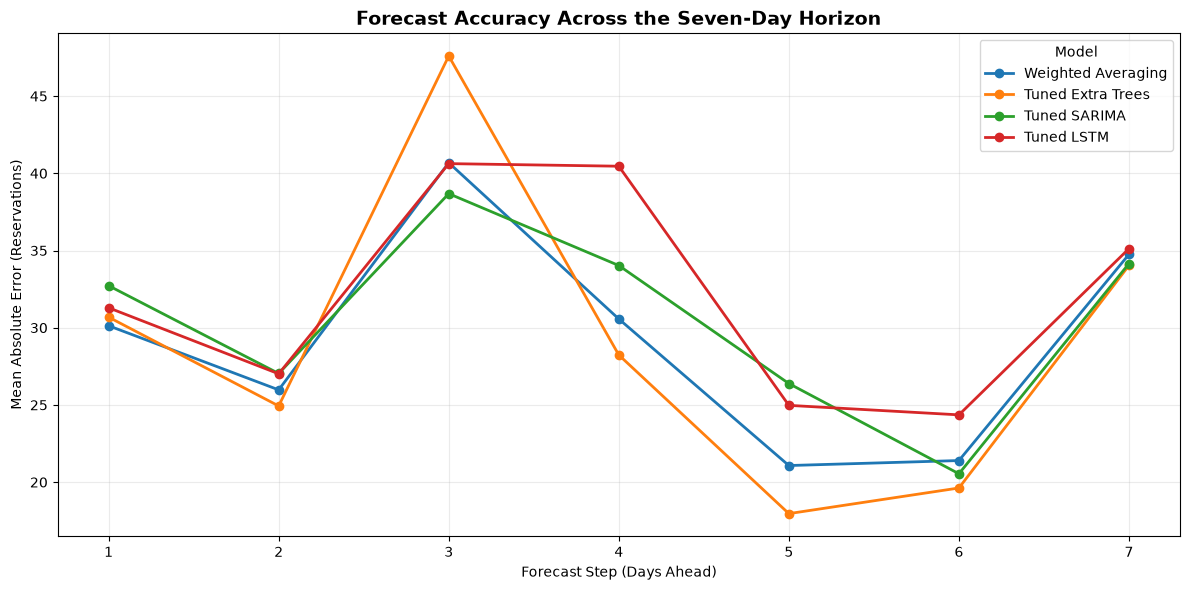

Forecast Horizon Performance Visualization Saved Successfully


In [26]:
fig, ax = plt.subplots(figsize=(12, 6))

for model_name in [
    "Weighted Averaging",
    "Tuned Extra Trees",
    "Tuned SARIMA",
    "Tuned LSTM"
]:
    model_data = horizon_performance_df[
        horizon_performance_df["Model"] == model_name
    ].sort_values("Forecast_Step")

    ax.plot(
        model_data["Forecast_Step"],
        model_data["MAE"],
        marker="o",
        linewidth=2,
        markersize=6,
        label=model_name
    )

ax.set_title(
    "Forecast Accuracy Across the Seven-Day Horizon",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Forecast Step (Days Ahead)")
ax.set_ylabel("Mean Absolute Error (Reservations)")
ax.set_xticks(range(1, forecast_horizon + 1))
ax.grid(alpha=0.25)
ax.legend(title="Model")

plt.tight_layout()

figure_path = artifacts_dir.parent / "reports" / "figures"
figure_path.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_path / "forecast_horizon_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Forecast Horizon Performance Visualization Saved Successfully")

#### Analyzing Forecast Errors Across Reservation Levels

In [27]:
volume_analysis_df = test_predictions_df.copy()

volume_thresholds = (
    test_df[target_column]
    .quantile([0.33, 0.67])
    .to_numpy()
)

if volume_thresholds[0] >= volume_thresholds[1]:
    raise ValueError(
        "Reservation-volume thresholds are not distinct."
    )

volume_analysis_df["Reservation_Level"] = pd.cut(
    volume_analysis_df["Actual"],
    bins=[
        -np.inf,
        volume_thresholds[0],
        volume_thresholds[1],
        np.inf
    ],
    labels=[
        "Low",
        "Moderate",
        "High"
    ],
    include_lowest=True
)

volume_analysis_df["Absolute_Error"] = (
    volume_analysis_df["Actual"]
    - volume_analysis_df["Predicted"]
).abs()

volume_performance_df = (
    volume_analysis_df
    .groupby(
        ["Model", "Reservation_Level"],
        observed=True
    )
    .apply(
        lambda group: pd.Series({
            **evaluate_forecast(
                group["Actual"].to_numpy(),
                group["Predicted"].to_numpy()
            ),
            "Observations": len(group),
            "Average_Actual_Reservations": group["Actual"].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

volume_performance_df["Observations"] = (
    volume_performance_df["Observations"].astype(int)
)

volume_performance_df.to_csv(
    artifacts_dir / "reservation_level_performance.csv",
    index=False
)

print("Reservation-Level Forecast Analysis Completed Successfully")

print("\nReservation-Level Thresholds:")
print(f"Low: Up to {volume_thresholds[0]:.2f} reservations")
print(
    f"Moderate: Above {volume_thresholds[0]:.2f} "
    f"to {volume_thresholds[1]:.2f} reservations"
)
print(f"High: Above {volume_thresholds[1]:.2f} reservations")

print("\nMAE by Reservation Level:")
display(
    volume_performance_df.pivot(
        index="Reservation_Level",
        columns="Model",
        values="MAE"
    ).round(4)
)

print("\nComplete Reservation-Level Performance:")
display(volume_performance_df.round(4))

Reservation-Level Forecast Analysis Completed Successfully

Reservation-Level Thresholds:
Low: Up to 61.97 reservations
Moderate: Above 61.97 to 98.03 reservations
High: Above 98.03 reservations

MAE by Reservation Level:


Model,Tuned Extra Trees,Tuned LSTM,Tuned SARIMA,Weighted Averaging
Reservation_Level,,,,
Low,28.8558,31.7756,32.0328,29.5719
Moderate,20.7502,13.7707,19.6454,16.2395
High,38.0051,51.5250,40.6231,42.6530



Complete Reservation-Level Performance:


,Model,Reservation_Level,MAE,RMSE,WAPE,R2,Observations,Average_Actual_Reservations
0,Tuned Extra Trees,Low,28.8558,34.9360,63.0727,-11.0488,36,45.7500
1,Tuned Extra Trees,Moderate,20.7502,26.6732,25.2241,-6.4246,38,82.2632
2,Tuned Extra Trees,High,38.0051,47.6884,27.6848,-1.5428,36,137.2778
3,Tuned LSTM,Low,31.7756,35.8299,69.4548,-11.6732,36,45.7500
4,Tuned LSTM,Moderate,13.7707,17.2661,16.7398,-2.1111,38,82.2632
5,Tuned LSTM,High,51.5250,60.5227,37.5334,-3.0956,36,137.2778
6,Tuned SARIMA,Low,32.0328,38.0575,70.0171,-13.2981,36,45.7500
7,Tuned SARIMA,Moderate,19.6454,24.2460,23.8812,-5.1348,38,82.2632
8,Tuned SARIMA,High,40.6231,49.8844,29.5919,-1.7824,36,137.2778
9,Weighted Averaging,Low,29.5719,34.9018,64.6381,-11.0252,36,45.7500


**Key Observations**

- **Reservation-Level Accuracy:** All four models achieved their lowest MAE on moderate-volume days, while high-volume days produced the largest absolute errors. Tuned LSTM performed best in the moderate category (MAE: 13.77) but struggled most with high-volume reservations (MAE: 51.53).
- **High-Volume Forecasting Challenges:** Tuned Extra Trees achieved the lowest MAE for both low-volume (28.86) and high-volume (38.01) days, demonstrating comparatively stronger performance at the extremes. However, low-volume days showed substantial relative errors across all models, with WAPE ranging from 63.07% to 70.02%.

#### Visualizing Forecast Performance Across Reservation Levels

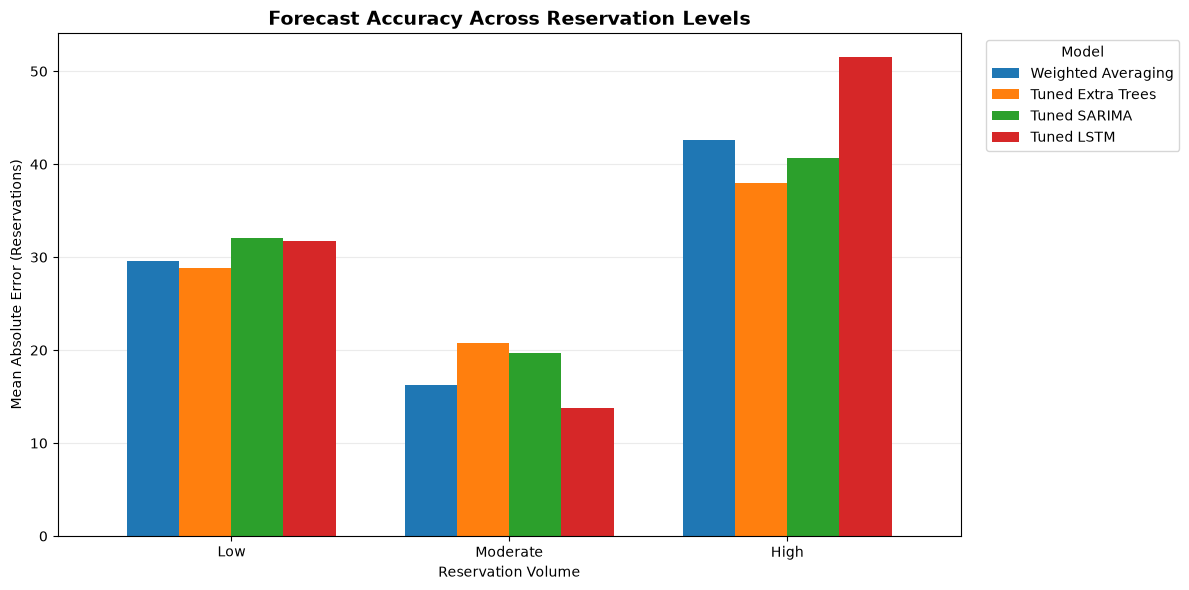

Reservation-Level Performance Visualization Saved Successfully


In [28]:
volume_plot_df = (
    volume_performance_df
    .pivot(
        index="Reservation_Level",
        columns="Model",
        values="MAE"
    )
    .reindex(["Low", "Moderate", "High"])
    [
        [
            "Weighted Averaging",
            "Tuned Extra Trees",
            "Tuned SARIMA",
            "Tuned LSTM"
        ]
    ]
)

ax = volume_plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

ax.set_title(
    "Forecast Accuracy Across Reservation Levels",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Reservation Volume")
ax.set_ylabel("Mean Absolute Error (Reservations)")
ax.set_xticklabels(
    volume_plot_df.index,
    rotation=0
)

ax.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    figure_path / "reservation_level_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Reservation-Level Performance Visualization Saved Successfully")

#### Consolidating Final Model Evaluation Results

In [29]:
final_evaluation_df = test_comparison_df.copy()

final_evaluation_df["Validation_MAE"] = final_evaluation_df["Model"].map(
    model_comparison_df.set_index("Model")["MAE"]
)

final_evaluation_df["Test_MAE_Rank"] = (
    final_evaluation_df["MAE"]
    .rank(method="min")
    .astype(int)
)

final_evaluation_df["Validation_MAE_Rank"] = (
    final_evaluation_df["Validation_MAE"]
    .rank(method="min")
    .astype(int)
)

final_evaluation_df["Model_Role"] = np.where(
    final_evaluation_df["Model"] == selected_config["primary_model"],
    "Validation-Selected Primary Model",
    "Comparison Model"
)

final_evaluation_df = final_evaluation_df.sort_values(
    ["Validation_MAE_Rank", "Test_MAE_Rank"]
).reset_index(drop=True)

final_evaluation_df.to_csv(
    artifacts_dir / "final_model_evaluation.csv",
    index=False
)

print("Final Model Evaluation Consolidated Successfully")

print("\nFinal Model Evaluation:")
display(final_evaluation_df.round(4))

primary_model = selected_config["primary_model"]

primary_results = final_evaluation_df.loc[
    final_evaluation_df["Model"] == primary_model
].iloc[0]

test_best = final_evaluation_df.loc[
    final_evaluation_df["MAE"].idxmin()
]

print(f"\nValidation-Selected Primary Model: {primary_model}")
print(f"Primary Model Validation MAE: {primary_results['Validation_MAE']:.4f}")
print(f"Primary Model Test MAE: {primary_results['MAE']:.4f}")

print(f"\nLowest Test MAE Model: {test_best['Model']}")
print(f"Lowest Test MAE: {test_best['MAE']:.4f}")

print(f"\nTotal Models Evaluated: {len(final_evaluation_df)}")
print(f"Total Test Days: {len(test_df)}")
print(f"Forecast Horizon: {forecast_horizon} days")

Final Model Evaluation Consolidated Successfully

Final Model Evaluation:


,Model,MAE,RMSE,WAPE,R2,Forecast_Days,Evaluation_Windows,Validation_MAE,Test_MAE_Rank,Validation_MAE_Rank,Model_Role
0,Weighted Averaging,29.2473,37.6373,33.1158,0.1901,110,16,24.8586,2,1,Validation-Selected Primary Model
1,Tuned LSTM,32.0191,41.4961,36.2543,0.0156,110,16,24.9624,4,2,Comparison Model
2,Tuned SARIMA,30.5649,38.6199,34.6077,0.1473,110,16,25.3564,3,3,Comparison Model
3,Tuned Extra Trees,29.0500,37.2760,32.8924,0.2056,110,16,25.6465,1,4,Comparison Model



Validation-Selected Primary Model: Weighted Averaging
Primary Model Validation MAE: 24.8586
Primary Model Test MAE: 29.2473

Lowest Test MAE Model: Tuned Extra Trees
Lowest Test MAE: 29.0500

Total Models Evaluated: 4
Total Test Days: 110
Forecast Horizon: 7 days


**Key Observations**

- **Primary Model Performance:** Weighted Averaging achieved the lowest validation MAE (24.86) among the 28 evaluated configurations and recorded a test MAE of 29.25, RMSE of 37.64, WAPE of 33.12%, and R² of 0.19 across 110 test days.
- **Final Model Comparison:** Tuned Extra Trees achieved the lowest test MAE (29.05), outperforming Weighted Averaging by just 0.20 reservations per day. However, Weighted Averaging remains the primary model because selection was based on validation results rather than test performance.

## Notebook Summary

This notebook evaluated the forecasting performance of four shortlisted models—Weighted Averaging, Tuned LSTM, Tuned SARIMA, and Tuned Extra Trees—using a chronological holdout test set comprising 110 days. Predictions were generated through 16 rolling-origin evaluation windows, maintaining the seven-day forecasting horizon established during model development.

**Key Findings**

- **Model Performance:** Weighted Averaging, the validation-selected primary model, achieved a test MAE of 29.25, RMSE of 37.64, WAPE of 33.12%, and R² of 0.19. Tuned Extra Trees achieved the lowest test MAE of 29.05, marginally outperforming the primary model.
- **Forecast Error Patterns:** Weighted Averaging demonstrated the lowest overall signed bias, while Tuned Extra Trees exhibited the lowest error variability. All models experienced substantial individual forecasting errors, indicating limitations in predicting unusually large fluctuations.
- **Forecast Horizon Performance:** Prediction errors varied across the seven-day horizon without consistently increasing over longer forecast steps. The third forecast step produced the highest MAE across all four models.
- **Reservation-Level Performance:** All models achieved their lowest absolute errors on moderate-volume days, while high-volume days were more challenging. Tuned Extra Trees demonstrated comparatively stronger performance across low- and high-volume reservation levels.
- **Model Selection:** Weighted Averaging remains the primary forecasting model because it achieved the lowest validation MAE of 24.86. The holdout test results were used exclusively for final evaluation rather than model reselection or hyperparameter tuning.

**Conclusion**

The evaluation demonstrates that combining statistical, deep learning, and tree-based forecasting approaches provides competitive predictive performance, although substantial errors remain across different reservation volumes and forecast periods. The results establish a transparent assessment of model accuracy, forecasting stability, and generalization performance while preserving the integrity of the chronological evaluation process.

The next notebook focuses on model explainability, examining ensemble component contributions and the influence of historical reservation patterns and engineered features on forecasting predictions.